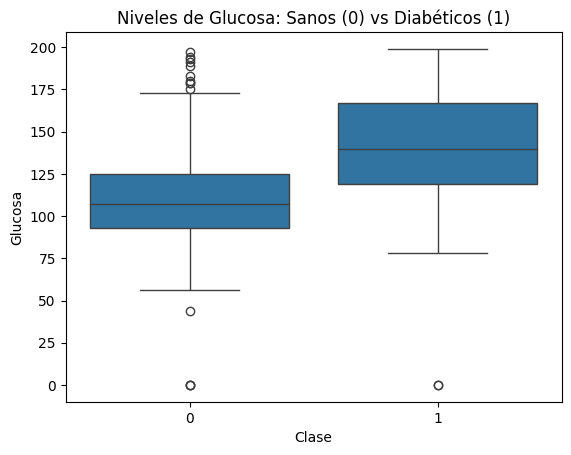

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Cargar desde URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = ['Embarazos', 'Glucosa', 'Presion', 'Piel', 'Insulina', 'IMC', 'Pedigree', 'Edad', 'Clase']
diabetes = pd.read_csv(url, names=columnas)

# Visualizar
sns.boxplot(x='Clase', y='Glucosa', data=diabetes)
plt.title("Niveles de Glucosa: Sanos (0) vs Diabéticos (1)")
plt.show()

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = diabetes.drop('Clase', axis=1)
y = diabetes['Clase']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar (aumentamos iteraciones para que converja bien)
modelo_diabetes = LogisticRegression(max_iter=1000)
modelo_diabetes.fit(X_train, y_train)

# Ver coeficientes
coefs = pd.DataFrame(modelo_diabetes.coef_[0], X.columns, columns=['Peso'])
print(coefs.sort_values(by='Peso', ascending=False))

               Peso
Pedigree   0.626741
IMC        0.102607
Embarazos  0.064376
Edad       0.037096
Glucosa    0.034095
Piel       0.003292
Insulina  -0.001804
Presion   -0.013879


In [4]:
# Predecir probabilidad para los primeros 5 pacientes del test
# La columna de la derecha [:, 1] es la probabilidad de "Tener Diabetes"
probs = modelo_diabetes.predict_proba(X_test)[:10, 1]
clases_reales = y_test[:10].values

for p, real in zip(probs, clases_reales):
    print(f"Probabilidad: {p:.2%} -> Realidad: {'Diabético' if real==1 else 'Sano'}")

Probabilidad: 27.59% -> Realidad: Sano
Probabilidad: 18.84% -> Realidad: Sano
Probabilidad: 11.45% -> Realidad: Sano
Probabilidad: 16.35% -> Realidad: Sano
Probabilidad: 47.15% -> Realidad: Sano
Probabilidad: 44.18% -> Realidad: Sano
Probabilidad: 1.55% -> Realidad: Sano
Probabilidad: 66.08% -> Realidad: Sano
Probabilidad: 54.15% -> Realidad: Sano
Probabilidad: 77.73% -> Realidad: Sano


In [ ]:
coeff_df = pd.DataFrame(logmodel.coef_[0], X.columns, columns=['Coeficiente'])
print(coeff_df)